# 02 · 双塔：源码、张量、梯度与真实训练
## Goal
从可编辑的 Python 网络走到真实训练。你可以改维度、历史窗口、学习率，也可以在左侧文件浏览器中打开 `reclab/models.py` 修改正式网络。

**Run All 会在最后创建一个新模型版本**，保留原来的数据和模型。本教程先做小 Batch 数学检查，再运行项目的共享训练器；不使用测试集。

## Setup
使用项目的 **Recommendation Lab (Python 3.12)** 内核。下面的用户和物品来自现有真实训练集；小 Batch 实验只是检查梯度，不能证明推荐效果提升。

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json

plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


In [2]:
import torch
from torch import nn
from torch.nn import functional as F
import reclab.models as model_module
from reclab.models import TwoTower
torch.set_num_threads(4)
torch.manual_seed(42)
DIM = 32
HISTORY_LEN = 20
BATCH = 8
TEMPERATURE = 0.1

## Steps
### 1. 直接看当前网络源码
这就是网页服务使用的类。要修改它，在左侧打开 `reclab/models.py`；保存后重启内核再从头执行，或使用最后训练格中的模块 reload。

In [3]:
print(inspect.getfile(TwoTower))
display(Code(inspect.getsource(TwoTower), language="python"))

/Users/lizuolin/local/recommendation-lab/reclab/models.py


class TwoTower(nn.Module):
    def __init__(self, n_users, n_items, dim=32, use_history=True, dropout=0.1):
        super().__init__()
        self.use_history = use_history
        self.user_embedding = nn.Embedding(n_users, dim)
        self.item_embedding = nn.Embedding(n_items, dim, padding_idx=0)
        self.user_mlp = nn.Sequential(
            nn.Linear(dim * 2, dim * 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim * 2, dim),
        )
        self.item_mlp = nn.Sequential(
            nn.Linear(dim, dim * 2), nn.ReLU(), nn.Linear(dim * 2, dim)
        )

    def encode_user(self, users, history):
        mask = (history != 0).unsqueeze(-1)
        pooled = (self.item_embedding(history) * mask).sum(1) / mask.sum(1).clamp_min(1)
        if not self.use_history:
            pooled = torch.zeros_like(pooled)
        return F.normalize(
            self.user_mlp(torch.cat([self.user_embedding(users), pooled], dim=-1)),
            dim=-1,
        )

    def encode_item(self, items):
        return F.normalize(self.item_mlp(self.item_embedding(items)), dim=-1)

    def loss(self, users, history, targets, temperature=0.1, logq=None):
        # In-batch sampled softmax. Duplicate positive IDs are accidental hits, not negatives.
        logits = (
            self.encode_user(users, history) @ self.encode_item(targets).T / temperature
        )
        if logq is not None:
            logits = logits - logq[targets][None, :]
        duplicate = targets[:, None].eq(targets[None, :])
        duplicate.fill_diagonal_(False)
        logits = logits.masked_fill(duplicate, -1e9)
        return F.cross_entropy(logits, torch.arange(len(users), device=users.device))

### 2. 用真实样本追踪张量形状
用户 `[B]`、历史 `[B,N]`、目标 `[B]`。两侧编码后都是 `[B,D]`；用户向量乘目标向量转置得到 `[B,B]`。

In [4]:
users_np, histories_np, targets_np, times_np = dataset.examples(HISTORY_LEN)
users = torch.from_numpy(users_np[:BATCH])
histories = torch.from_numpy(histories_np[:BATCH])
targets = torch.from_numpy(targets_np[:BATCH])
model = TwoTower(dataset.n_users, dataset.n_items, dim=DIM, use_history=True, dropout=0.0)
model.eval()  # 固定本次数学诊断；eval 不等于关闭 autograd
user_vectors = model.encode_user(users, histories)
item_vectors = model.encode_item(targets)
display(pd.DataFrame({"tensor": ["users", "histories", "targets", "user_vectors", "item_vectors"],
    "shape": [list(x.shape) for x in [users, histories, targets, user_vectors, item_vectors]]}))
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
assert torch.allclose(user_vectors.norm(dim=1), torch.ones(BATCH), atol=1e-6)

,tensor,shape
0,users,[8]
1,histories,"[8, 20]"
2,targets,[8]
3,user_vectors,"[8, 32]"
4,item_vectors,"[8, 32]"


Trainable parameters: 385952


### 3. 把 sampled softmax 损失展开
先预测：降低温度会让分布更尖锐，还是更平滑？

每行的正确类别在对角线。其他目标是 batch 内采样负例，重复目标会屏蔽。这里不启用 LogQ，便于先核对基本数学；它们并不是真实“曝光未点击”。

In [5]:
cosine = user_vectors @ item_vectors.T
duplicate = targets[:, None].eq(targets[None, :])
duplicate.fill_diagonal_(False)
logits = (cosine / TEMPERATURE).masked_fill(duplicate, -1e9)
logits.retain_grad()
labels = torch.arange(BATCH)
probabilities = logits.softmax(dim=1)
loss = F.cross_entropy(logits, labels)
model.zero_grad(set_to_none=True)
loss.backward()
expected_gradient = (probabilities.detach() - F.one_hot(labels, BATCH)) / BATCH
assert torch.allclose(logits.grad, expected_gradient, atol=1e-6)
display(pd.DataFrame(probabilities.detach().numpy(), index=users.tolist(), columns=targets.tolist()))
print("Cross-entropy:", float(loss.detach()))
print("dL/dlogit for row 0:", logits.grad[0].tolist())

,180,270,97,3456,2400,1265,3361,4624
0,0.075222,0.004755,0.016481,0.023495,0.147182,0.670796,0.012573,0.049495
0,0.097509,0.006899,0.040241,0.024322,0.198824,0.573799,0.008774,0.049632
0,0.067674,0.002751,0.012127,0.037660,0.259269,0.570432,0.022318,0.027770
0,0.109721,0.001928,0.027018,0.061421,0.187387,0.552615,0.017557,0.042352
0,0.127011,0.002267,0.028390,0.062393,0.160158,0.546719,0.018724,0.054338
1,0.144987,0.011143,0.200329,0.150079,0.215864,0.127405,0.128882,0.021311
1,0.135188,0.015927,0.120577,0.184901,0.181037,0.128408,0.208228,0.025733
1,0.114495,0.027263,0.112846,0.134311,0.165850,0.189183,0.218638,0.037414


Cross-entropy: 2.9391064643859863
dL/dlogit for row 0: [-0.115597203373909, 0.0005943385185673833, 0.002060179365798831, 0.002936860080808401, 0.01839778758585453, 0.08384954929351807, 0.00157161767128855, 0.006186868529766798]


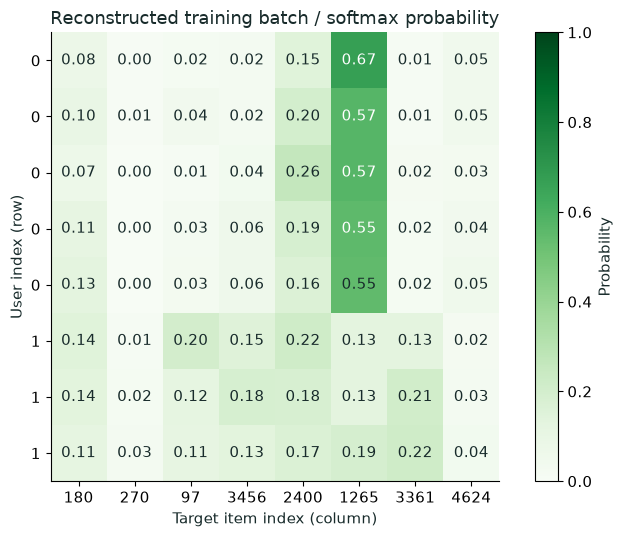

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
image = ax.imshow(probabilities.detach().numpy(), cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(BATCH), [str(i) for i in targets.tolist()])
ax.set_yticks(range(BATCH), [str(i) for i in users.tolist()])
ax.set(xlabel="Target item index (column)", ylabel="User index (row)",
       title="Reconstructed training batch / softmax probability")
for row in range(BATCH):
    for col in range(BATCH):
        value = float(probabilities[row, col].detach())
        text = "x" if duplicate[row, col] else f"{value:.2f}"
        ax.text(col, row, text, ha="center", va="center", color="white" if value > .55 else "#182b2b")
fig.colorbar(image, ax=ax, label="Probability")
plt.tight_layout(); plt.show()

### 4. 先让一个小 Batch 过拟合
这是训练代码的 sanity check。只更新 Notebook 内存中的新模型，不覆盖已保存的权重；小 Batch loss 下降不代表验证指标提高。

Tiny-batch loss: 2.9391064643859863 -> 0.18255160748958588


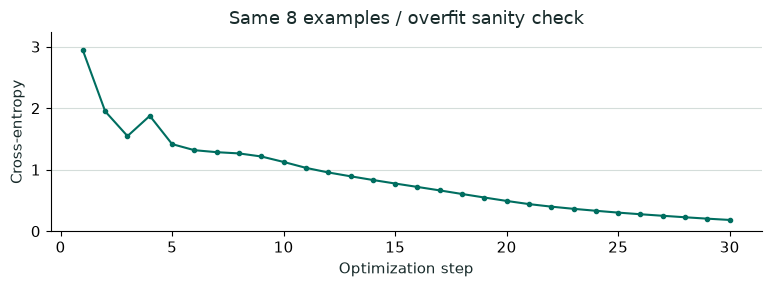

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
tiny_losses = []
for step in range(30):
    optimizer.zero_grad(set_to_none=True)
    tiny_loss = model.loss(users, histories, targets, TEMPERATURE)
    tiny_losses.append(float(tiny_loss.detach()))
    tiny_loss.backward()
    optimizer.step()
assert tiny_losses[-1] < tiny_losses[0]
print("Tiny-batch loss:", tiny_losses[0], "->", tiny_losses[-1])
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1,31), tiny_losses, color="#006e60", marker=".")
ax.set(xlabel="Optimization step", ylabel="Cross-entropy", title="Same 8 examples / overfit sanity check", ylim=(0, max(tiny_losses)*1.1))
ax.grid(axis="y"); plt.tight_layout(); plt.show()

### 5. 在本格里试着改网络
`MyTwoTower` 是一个独立学习分支，只检查前向传播。把 `ReLU` 换成 `Tanh`，或改 `HIDDEN`，观察参数量和输出形状。

这一格没有替换正式训练器。希望工作台使用新结构时，编辑真实的 `reclab/models.py`，然后运行下面的完整训练格。

In [8]:
HIDDEN = 16
class MyTwoTower(TwoTower):
    def __init__(self, n_users, n_items, dim):
        super().__init__(n_users, n_items, dim, use_history=True, dropout=0.0)
        self.user_mlp = nn.Sequential(nn.Linear(2*dim, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, dim))

sandbox = MyTwoTower(dataset.n_users, dataset.n_items, DIM)
print("Edited user tower:", sandbox.user_mlp)
print("Output shape:", tuple(sandbox.encode_user(users, histories).shape))
print("Parameters:", sum(p.numel() for p in sandbox.parameters()))

Edited user tower: Sequential(
  (0): Linear(in_features=64, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=32, bias=True)
)
Output shape: (8, 32)
Parameters: 381296


### 6. 跑项目真实训练器，保存新版本
先只改 `EXPERIMENT` 中一个变量。保存后的模型、配置、曲线会出现在网页“训练与实验”里（刷新页面）。它使用完整训练子集和固定验证口径，不使用上面的 8 条样本作为评估。

reload 会读取你已经保存的 `models.py` / `train.py`。修改结构后从新模型开始训练；不要用不兼容的新结构加载旧 checkpoint。

In [9]:
import importlib
import reclab.train as train_module
importlib.reload(model_module)
train_module = importlib.reload(train_module)

EXPERIMENT = train_module.TrainConfig(
    name="notebook / first-full-run", dim=32, history_len=20,
    epochs=4, batch_size=256, learning_rate=0.003,
    use_history=True, logq_correction=False, seed=42,
)
new_run = train_module.train(EXPERIMENT)
print("Saved run:", new_run["run_id"])
display(pd.Series(new_run["validation"]["metrics"], name="validation score").to_frame())

20261028T023407346105 {'epoch': 1, 'loss': 5.560806380245401, 'gradient_norm_before_clip': 0.3162150839824632, 'validation_ndcg@20': 0.0007904414175060725, 'validation_recall@20': 0.000609776941282452, 'elapsed_seconds': 1.81}


20261028T023407346105 {'epoch': 2, 'loss': 5.492199623965221, 'gradient_norm_before_clip': 0.32834317195863233, 'validation_ndcg@20': 0.008092865280543902, 'validation_recall@20': 0.014427202969790203, 'elapsed_seconds': 2.38}


20261028T023407346105 {'epoch': 3, 'loss': 5.232908364200719, 'gradient_norm_before_clip': 0.5570250882509169, 'validation_ndcg@20': 0.01700333691787301, 'validation_recall@20': 0.031168373965094427, 'elapsed_seconds': 2.93}


20261028T023407346105 {'epoch': 4, 'loss': 4.913768497700725, 'gradient_norm_before_clip': 0.7106661569904273, 'validation_ndcg@20': 0.017804264366807675, 'validation_recall@20': 0.03713369853338916, 'elapsed_seconds': 3.53}


Saved run: 20261028T023407346105


,validation score
recall@10,0.028066
ndcg@10,0.014543
mrr@10,0.011672
hit_rate@10,0.038348
recall@20,0.037134
ndcg@20,0.017804
mrr@20,0.013524
hit_rate@20,0.064897
recall@50,0.071146
ndcg@50,0.025709


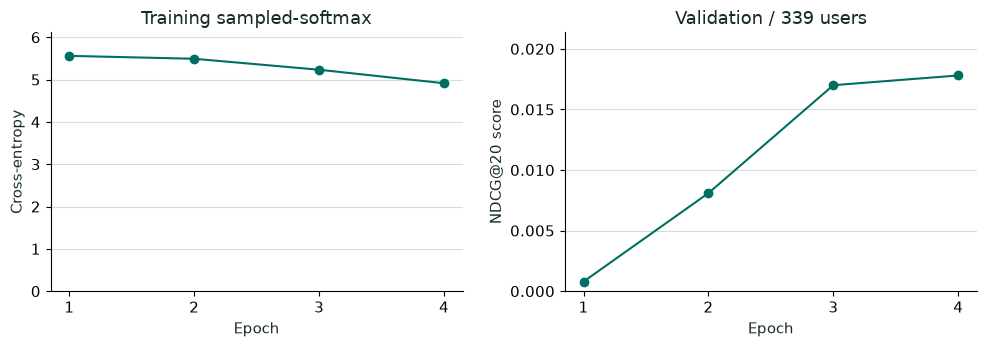

In [10]:
curve = pd.DataFrame(new_run["curve"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(curve.epoch, curve.loss, color="#006e60", marker="o")
axes[0].set(title="Training sampled-softmax", xlabel="Epoch", ylabel="Cross-entropy", ylim=(0, curve.loss.max()*1.1))
axes[1].plot(curve.epoch, curve["validation_ndcg@20"], color="#006e60", marker="o")
axes[1].set(title=f"Validation / {new_run['validation']['audit']['evaluated_users']} users", xlabel="Epoch", ylabel="NDCG@20 score", ylim=(0, max(curve["validation_ndcg@20"].max()*1.2, .001)))
for ax in axes:
    ax.set_xticks(curve.epoch)
    ax.grid(axis="y")
plt.tight_layout(); plt.show()

## Checks
本 Notebook 用断言检查了向量归一化、交叉熵梯度公式，以及真实小 Batch 能否优化。最终模型由验证 NDCG@20 选择 checkpoint，结果保存到 `artifacts/runs/<run_id>/`。

## Next Steps
先写下预测，再仅改变 `history_len` 或 `learning_rate` 重跑完整训练格。训练 loss 和验证指标是否同向变化？用 `configs/no-history.json` 对照历史特征的作用。

当前机制参考双塔模型、LastN 与 batch 内负样本讲义；这不是原论文数据与工业规模的完整复现。测试集保留给最终验收，继续实验不要围绕它调参。